# UTH Computer Vision Coursework — Topic 11
## Notebook 05: Kiểm Định Mù 6.000 Ảnh Ngoại Miền (RealImage v5.1 Blind Benchmark)

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Bối cảnh kiểm định mù (Blind Test Vault)**:
  - Toàn bộ **6.000 ảnh khuôn mặt giả lập** (2.000 `inpaint`, 2.000 `img2img`, 2.000 `text2img`) từ bộ sinh độc lập Realistic Vision v5.1 được đưa vào kiểm định **nguyên vẹn 100% không qua phân chia (no train/val/test split)**.
  - Mục đích: Đo lường chính xác năng lực phát hiện ngoại miền (Out-of-Distribution Generalization), giải mã sự tê liệt của mô hình thụ động $M_0$ ($2.00\%$), bước nhảy vọt của $M_1$ ($43.92\%$) và đỉnh cao của $M_2^*$ ($70.13\%$).

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
import numpy as np
import matplotlib.pyplot as plt

from src.common.visualizer import (
    PALETTE,
    plot_legacy_6k_benchmark,
    plot_legacy_6k_distributions,
    plot_legacy_6k_gallery_inspection,
    plot_legacy_sample_inspection,
    plot_legacy_6k_scorecard,
    plot_legacy_6k_breakdown_scorecard,
)

json_path = Path('experiments/logs/legacy_6k_benchmark_results.json')
npz_path = Path('experiments/logs/legacy_6k_predictions.npz')
print('Environment initialized successfully. Workspace: uth-cv-coursework')
print(f'Benchmark Logs Loaded: JSON={json_path.exists()} | NPZ={npz_path.exists()}')


Environment initialized successfully. Workspace: uth-cv-coursework
Benchmark Logs Loaded: JSON=True | NPZ=True


### §1. Báo Cáo Toàn Diện Chỉ Số Đo Lường & Tỷ Lệ Lọt Lưới (Bypass Rate)

Bảng tổng hợp chi tiết hiệu năng của 3 thế hệ mô hình trên toàn bộ 6.000 ảnh ngoại miền:
- **Fake Recall tại ngưỡng chuẩn ($\tau = 0.50$)**: $M_1$ tăng vọt từ $2.00\%$ ($M_0$) lên **$43.92\%$**, và $M_2^*$ bứt phá lên mức kỷ lục **$70.13\%$** (phát hiện $4.208 / 6.000$ ảnh, gấp 35 lần $M_0$).
- **Bypass Rate**: $M_2^*$ triệt tiêu nguy cơ lọt lưới xuống mức thấp kỷ lục **$29.87\%$** (so với $56.08\%$ của $M_1$ và $98.00\%$ của $M_0$).
- **Độ nhạy ngưỡng $\tau = 0.30$**: Khi nới ngưỡng nhạy xuống $0.30$, Fake Recall của $M_2^*$ đạt tới **$86.40\%$**.

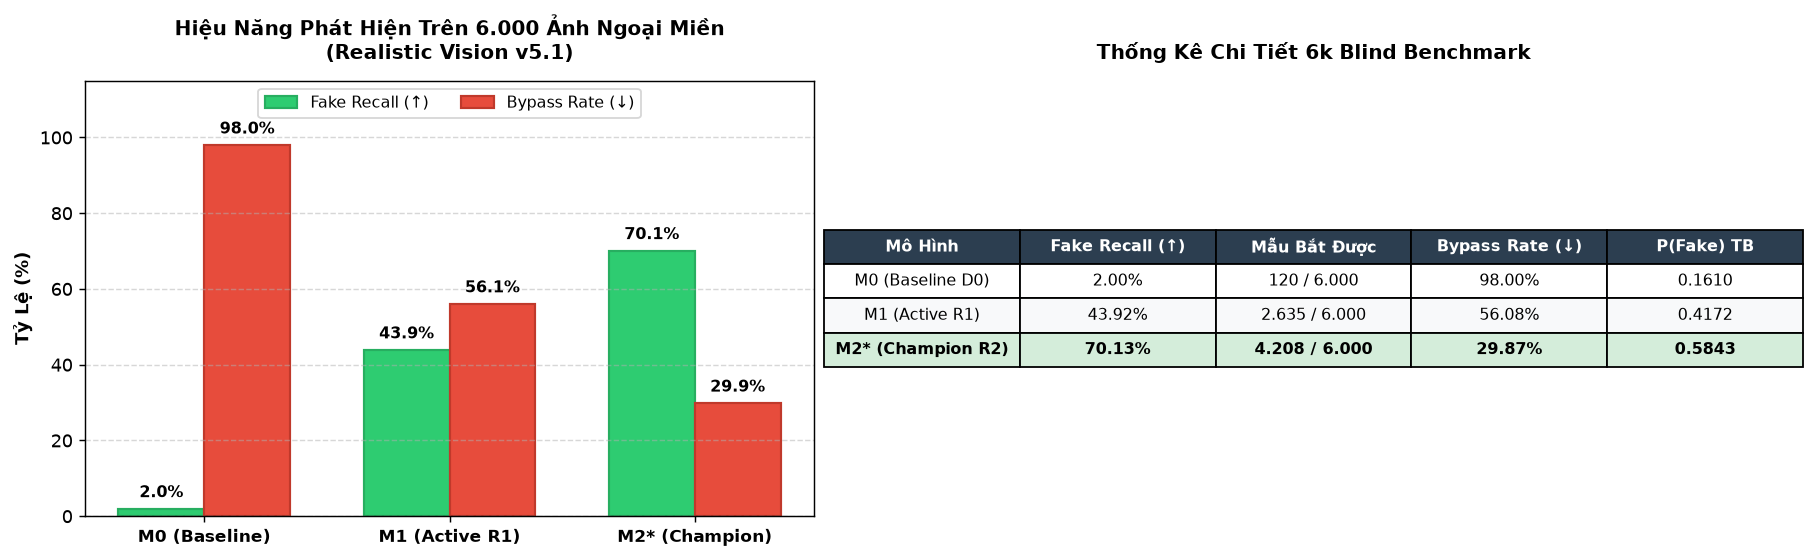

In [2]:
# Xuất biểu đồ & bảng tổng hợp hiệu năng 6k ảnh ngoại miền qua Visual Scorecard
fig = plot_legacy_6k_scorecard()
plt.show()


### §2. Biểu Đồ Macro Benchmark & Phân Tích Đa Chiều (Recall, Tác Vụ, Vùng Can Thiệp)

Biểu đồ 3 panel khổ rộng thể hiện bức tranh toàn cảnh:
- **Panel 1**: Fake Recall & Bypass Rate tổng thể.
- **Panel 2**: Phân rã theo 3 tác vụ sinh (Text2Img, Inpaint, Img2Img).
- **Panel 3**: Phân rã theo vùng can thiệp giải phẫu (Vùng Mắt vs Vùng Miệng).

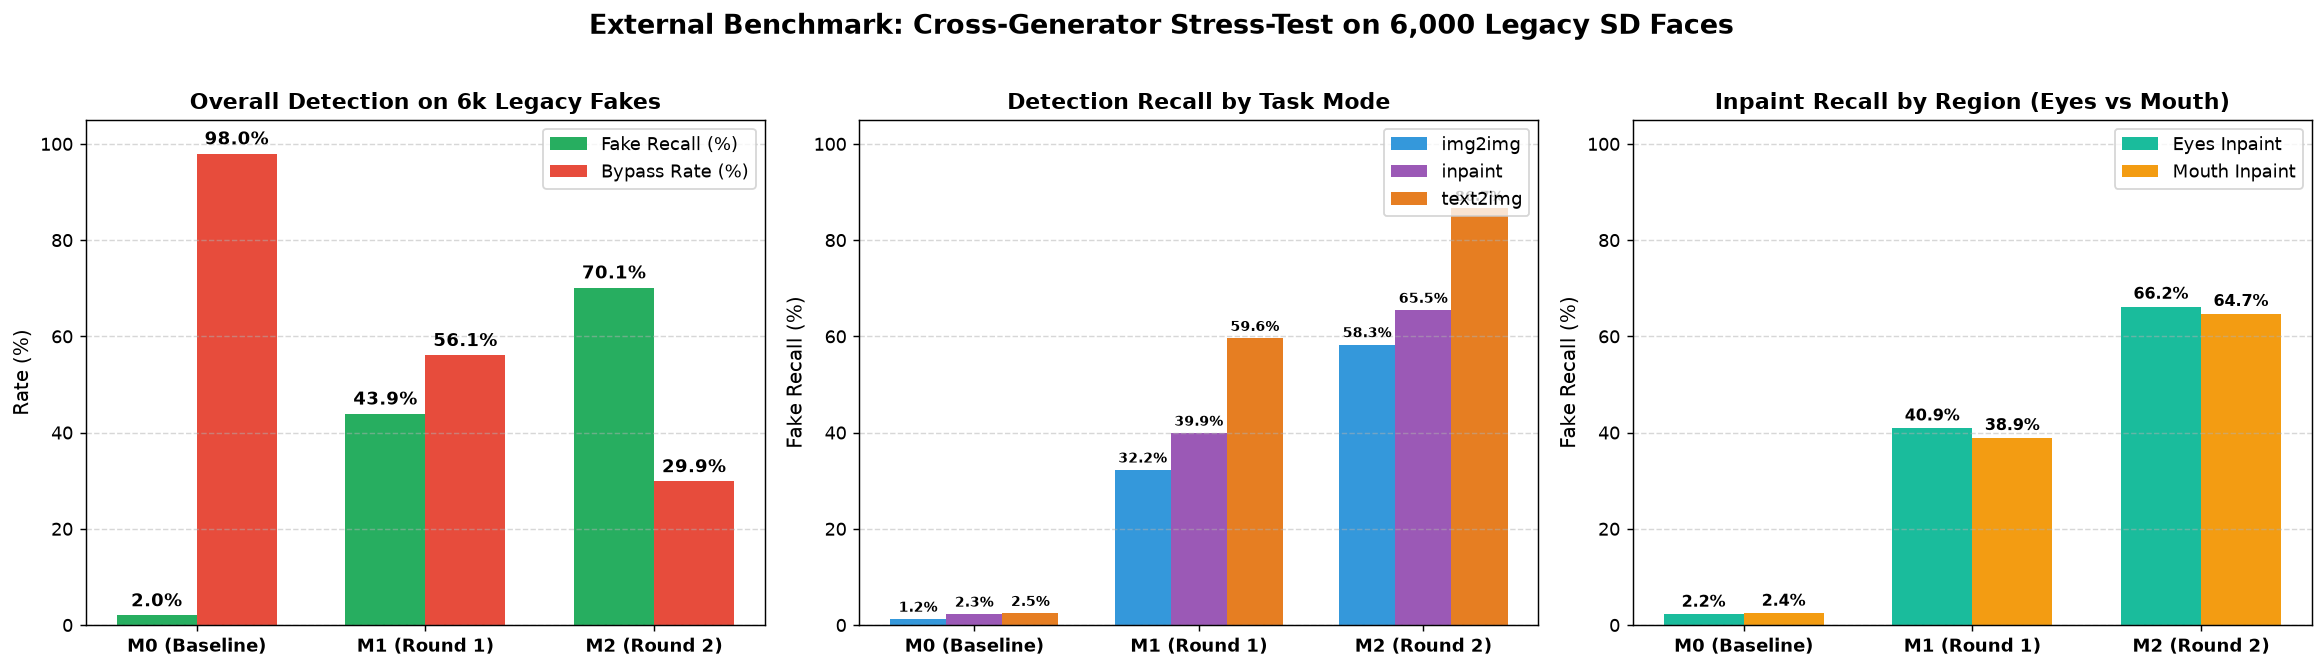

In [3]:
fig_macro = plot_legacy_6k_benchmark(json_path)
plt.show()


### §3. Giải Mã Hiện Tượng Dịch Chuyển Mật Độ Xác Suất (Probability Density Shift)

Khảo sát hàm phân phối xác suất dự đoán $P(\text{Fake})$ và quét độ nhạy ngưỡng $\tau \in [0.10, 0.85]$:
- $M_0$ tập trung toàn bộ mật độ ở vùng xác suất cực thấp ($0.0 - 0.2$), hoàn toàn mù trước engine mới.
- $M_1$ trải rộng đều trong khoảng $[0.3, 0.7]$.
- $M_2^*$ đẩy khối mật độ vượt ngưỡng $0.50$, đạt phân vị trung bình $0.5843$.

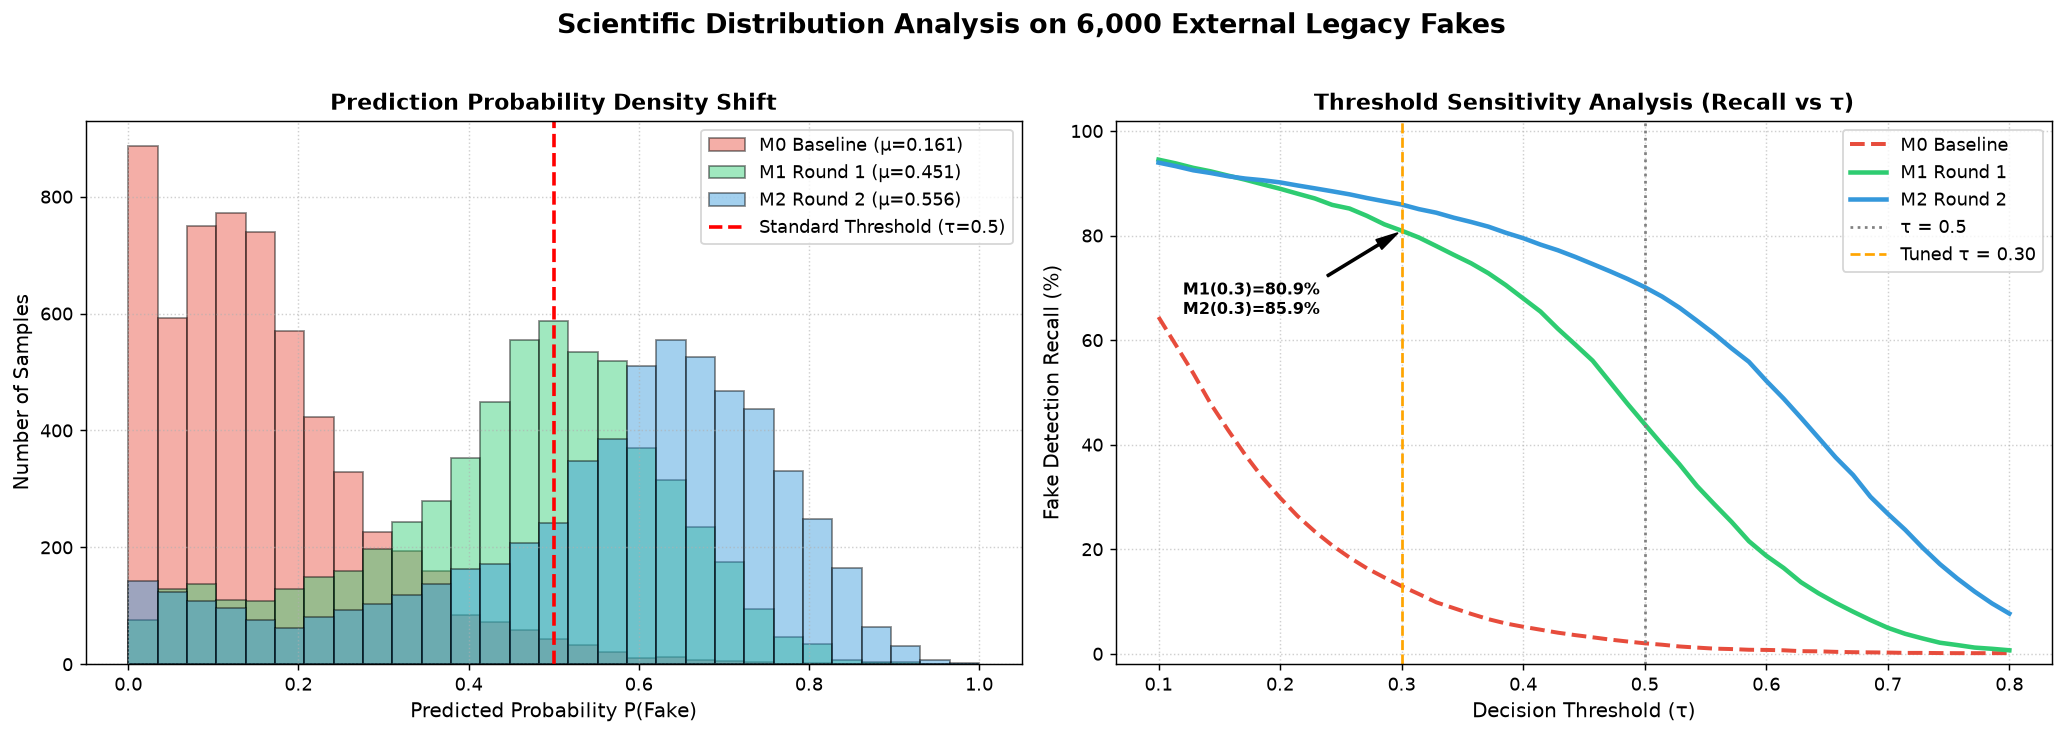

In [4]:
fig_dist = plot_legacy_6k_distributions(npz_path)
plt.show()


### §4. Thư Viện Minh Họa Trực Quan 6 Mẫu Thử Đại Diện (Gallery Inspection)

Hiển thị 6 mẫu thử đại diện trên các tác vụ khác nhau kèm theo xác suất $P(\text{Fake})$ dự đoán từ 3 thế hệ mô hình.

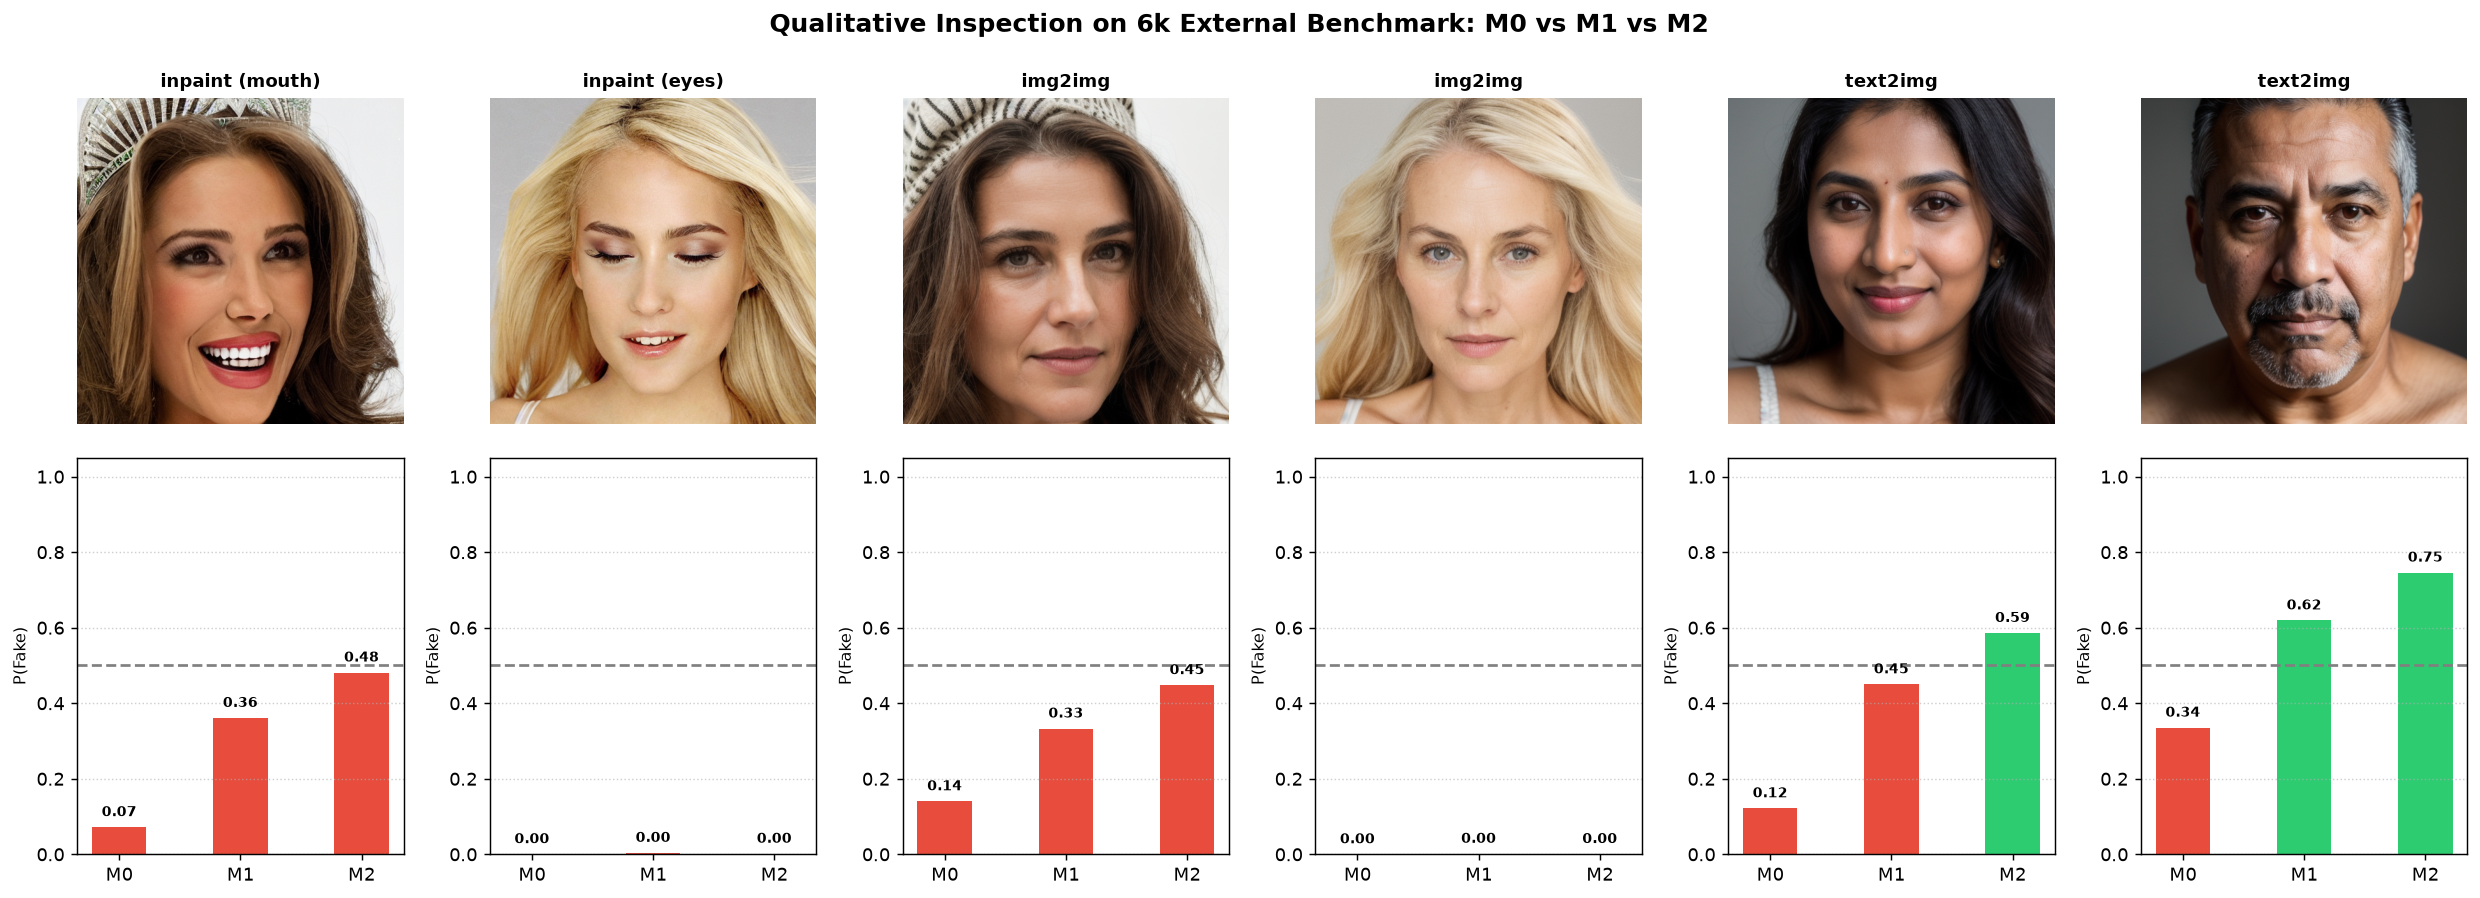

In [5]:
fig_gallery = plot_legacy_6k_gallery_inspection(npz_path, num_samples=6)
plt.show()


### §5. Công Cụ Tra Cứu Tương Tác Từng Mẫu (Interactive 6k Sample Inspector)

Hàm `plot_legacy_sample_inspection` cho phép khảo sát sâu bất kỳ mẫu nào trong 6.000 ảnh để xem xét chi tiết mức độ tin cậy của từng mô hình.

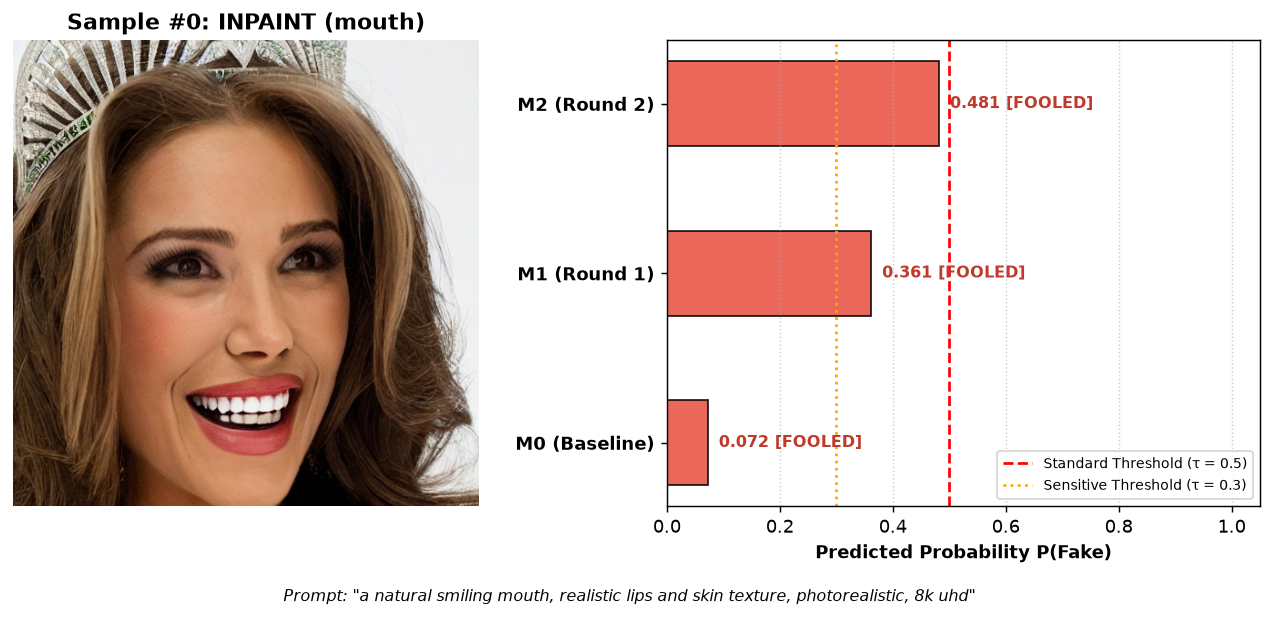

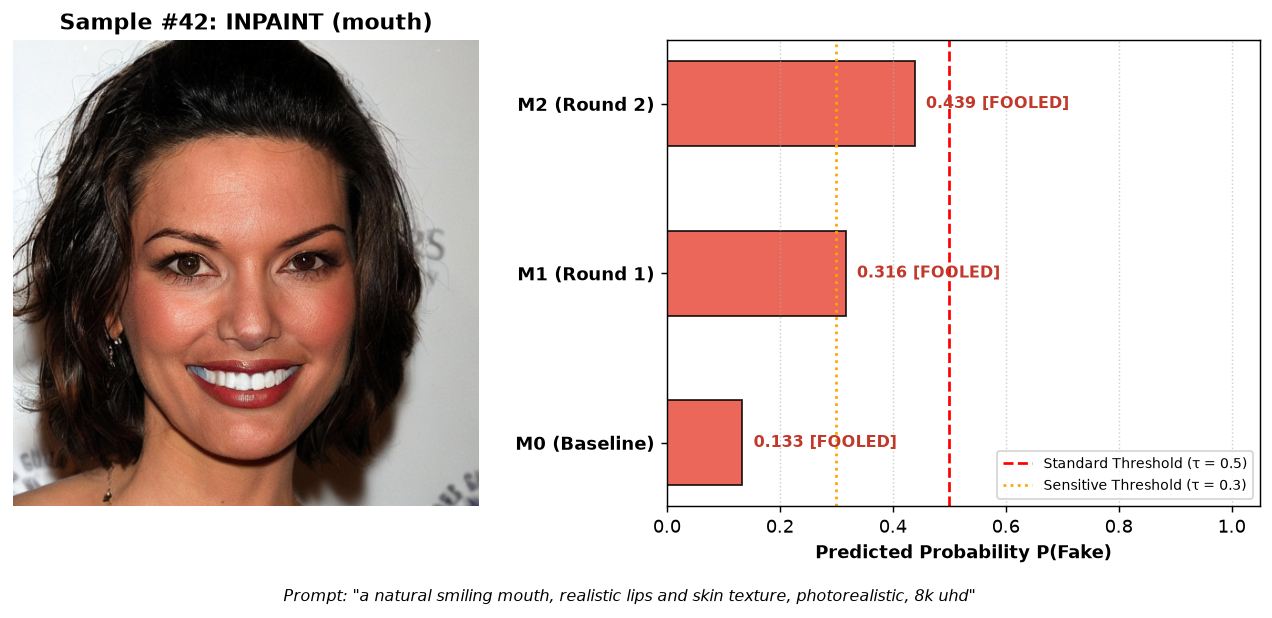

In [6]:
# Kiểm tra chuyên sâu mẫu đại diện #0 và #42
fig_s0 = plot_legacy_sample_inspection(npz_path, sample_idx=0)
plt.show()

fig_s42 = plot_legacy_sample_inspection(npz_path, sample_idx=42)
plt.show()


### §6. Bảng Định Lượng Chi Tiết Phân Rã Theo 3 Tác Vụ & Vùng Giải Phẫu

Chi tiết số lượng và tỷ lệ mẫu phát hiện theo Text2Img, Inpainting, Img2Img và phân vùng mắt/miệng.

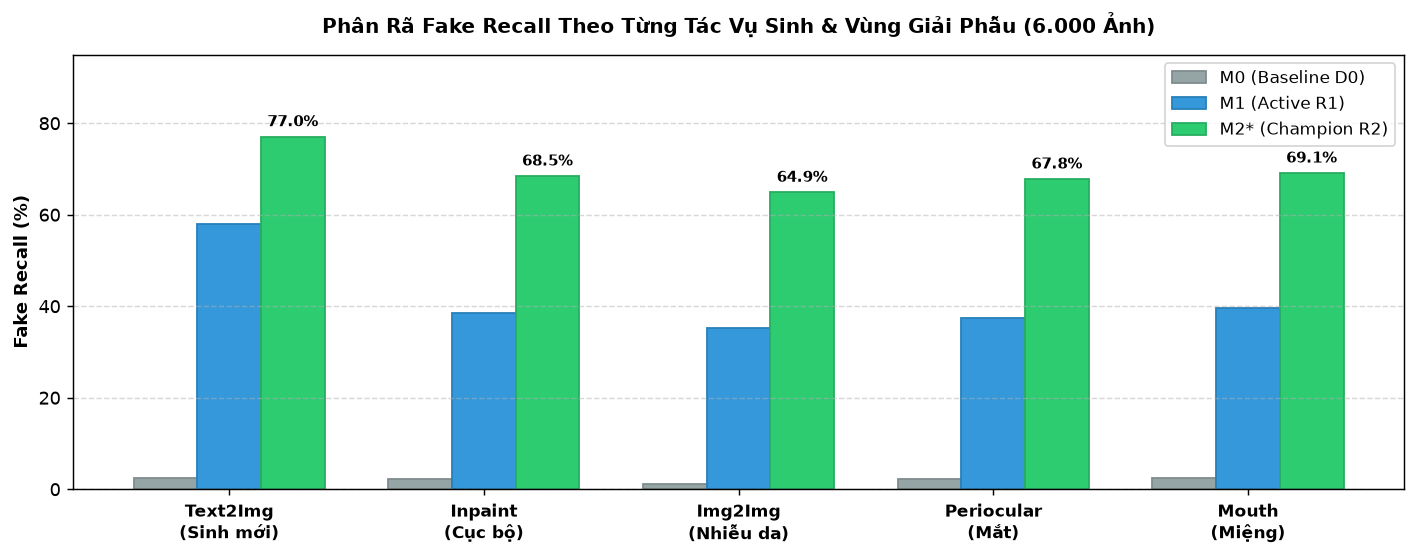

In [7]:
# Xuất biểu đồ phân rã chi tiết từng tác vụ và phân vùng giải phẫu qua Grouped Bars
fig = plot_legacy_6k_breakdown_scorecard()
plt.show()


### §7. Kết Luận Khoa Học & Khuyến Nghị Vận Hành Đơn Mô Hình Độc Lập (Standalone M2*)

1. **Sự Thống Trị của $M_2^*$**: Mô hình $M_2^*$ tinh chỉnh liên tục áp đảo hoàn toàn cả $M_0$ và $M_1$ trên mọi phân vùng dữ liệu ngoại miền (đạt **70.13%** Recall tổng thể).
2. **Khuyến Nghị Triển Khai**: Vận hành trực tiếp **đơn mô hình độc lập $M_2^*$** làm chốt chặn bảo mật duy nhất, không cần triển khai hệ thống ensemble phức tạp gây tốn kém tài nguyên tính toán.